# A minimal model of shared knowledge and self-correction

Code accompanying *Will AI make shared knowledge collapse?* It defines the model used in the paper and reproduces Figure 1 and every model result reported in the text.

**Requirements.** Python 3 with numpy, pandas and matplotlib (run with Python 3.9.6, numpy 1.26.4, pandas 2.2.3 and matplotlib 3.5.3; an earlier run with Python 3.11.8, pandas 2.1.4 and matplotlib 3.8.0 gave identical results). Sections 1 to 9, 11 and 12 run in under a minute; the agent-based check in Section 10 takes a few minutes. Results are written to the folder `outputs/`.

**Contents.**
1. The model
2. The threshold stock and the settled stock
3. The three mechanisms in combination
4. A group that begins to learn through AI
5. When errors begin to accumulate
6. Robustness to the fixed settings and to how discoveries are interpreted
7. Two stable states above the threshold
8. Reliance that responds to noticed failures
9. Figure 1
10. Agent-based check of the equations
11. The tipping point
12. Recovery after the tipping point

## 1. The model

A group holds a stock of $K$ items, a share $w$ of which are wrong. In each generation:

1. **Testing.** Each of $N$ people has $E$ experiences spread at random over the stock. An item is tested by a given person with probability $q = 1 - e^{-E/K}$ and by at least one person with probability $Q = 1 - e^{-NE/K}$. A test corrects a wrong item only if it is interpreted correctly, which happens with probability $R(w) = A + (1 - A)(1 - w)^M$. The exponent $M$ sets **independent detection**: the larger $M$, the faster interpretation deteriorates as errors accumulate.
2. **Transmission.** The next generation learns each item from someone who tested it with probability $r$ (**tests that travel**), if anyone did, and otherwise from a randomly chosen person. Copying introduces errors at rate $\varepsilon$.
3. **Forgetting.** An item that nobody tested fades with probability $f$ (**use-dependent forgetting**).
4. **New items.** $G$ new items enter, each right with probability $P_0 R(w)$, because discoveries are also interpreted through existing knowledge.

Each mechanism has a strong value (a group that learns from people and experience) and a weak value (a group that learns through AI).

In [1]:
import os, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = 'outputs'; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'font.family': 'Arial', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# fixed settings
BASE = dict(N=50, E=100, EPS=0.02, A=0.02, P0=0.9, G=50)
K0, W0 = 1000, 0.05                      # initial stock and share wrong
# the three mechanisms: M = independent detection, r = tests that travel, f = use-dependent forgetting
STRONG = dict(M=1, r=0.5, f=0.2)
WEAK   = dict(M=3, r=0.3, f=0.0)
SWITCH, T = 150, 600                     # generation at which the group begins to learn through AI; run length

def read(w, M, prm=BASE):
    """Probability that a test is interpreted correctly when a share w of items is wrong."""
    return prm['A'] + (1 - prm['A']) * (1 - w) ** M

def step(w, K, M, r, f, prm=BASE, g=None, discovery='through knowledge'):
    """One generation. Returns the new share wrong and the new stock."""
    g = prm['G'] if g is None else g
    q = 1 - np.exp(-prm['E'] / K)                    # tested by a given person
    Q = 1 - np.exp(-prm['N'] * prm['E'] / K)         # tested by at least one person
    R = read(w, M, prm)
    wrong = r * Q * w * (1 - R) + (1 - r) * (Q * w - q * w * R) + (1 - Q) * (1 - f) * w
    keep = 1 - (1 - Q) * f                           # share of the stock not forgotten
    s = wrong / keep
    s = s + (1 - s) * prm['EPS']                     # copying error
    K_keep = K * keep
    p_new = prm['P0'] * R if discovery == 'through knowledge' else prm['P0']
    K_new = K_keep + g
    return (s * K_keep + (1 - p_new) * g) / K_new, K_new

def run(M, r, f, prm=BASE, T=T, switch_at=None, after=None, discovery='through knowledge'):
    """Trajectory over T generations, optionally switching to the mechanisms in `after` at generation switch_at."""
    w, K, rows = W0, K0, []
    for t in range(T):
        rows.append((t, K, w, K * (1 - w)))
        p = dict(M=M, r=r, f=f) if (switch_at is None or t < switch_at) else after
        w, K = step(w, K, prm=prm, discovery=discovery, **p)
    return pd.DataFrame(rows, columns=['gen', 'stock', 'share_wrong', 'correct'])

def mech(detection, travel, forgetting):
    """Mechanism values from 'strong'/'weak' labels."""
    pick = lambda lab, k: (STRONG if lab == 'strong' else WEAK)[k]
    return dict(M=pick(detection, 'M'), r=pick(travel, 'r'), f=pick(forgetting, 'f'))

protected = run(**STRONG)                                       # never learns through AI
with_ai = run(**STRONG, switch_at=SWITCH, after=WEAK)           # learns through AI from generation 150
print('model ready')

model ready


## 2. The threshold stock and the settled stock

At a fixed stock, the share of wrong items settles where corrections offset copying errors:

$$w\,[\varepsilon + (1-\varepsilon)\,R(w)\,C(K)] = \varepsilon, \qquad C(K) = r\,(1 - e^{-NE/K}) + (1 - r)(1 - e^{-E/K}).$$

The **threshold stock** is the stock at which this balance is reached with 10% of items wrong (a convention). With forgetting, the stock settles where the untested items forgotten in each generation equal the new items: $f K e^{-NE/K} = G$. The second table shows how the threshold changes across a range of values for tests that travel and independent detection.

In [2]:
def C(K, r, prm=BASE):
    return r * (1 - np.exp(-prm['N'] * prm['E'] / K)) + (1 - r) * (1 - np.exp(-prm['E'] / K))

def threshold_stock(M, r, prm=BASE, wc=0.10):
    need = prm['EPS'] * (1 - wc) / (wc * (1 - prm['EPS']) * read(wc, M, prm))
    if need >= 1: return 0.0
    lo, hi = 1.0, 1e9                                  # C falls as K grows
    while hi / lo > 1 + 1e-10:
        mid = np.sqrt(lo * hi)
        lo, hi = (mid, hi) if C(mid, r, prm) >= need else (lo, mid)
    return lo

def settled_stock(f, prm=BASE):
    if f == 0: return np.inf
    lo, hi = 1.0, 1e9
    while hi / lo > 1 + 1e-12:
        mid = np.sqrt(lo * hi)
        lo, hi = (mid, hi) if f * mid * np.exp(-prm['N'] * prm['E'] / mid) < prm['G'] else (lo, mid)
    return lo

K_settled = settled_stock(STRONG['f'])
s2 = pd.DataFrame([dict(independent_detection=i, tests_that_travel=t, **{k: v for k, v in mech(i, t, 'strong').items() if k != 'f'},
                        threshold_stock=threshold_stock(mech(i, t, 'strong')['M'], mech(i, t, 'strong')['r']))
                   for i, t in itertools.product(['strong', 'weak'], repeat=2)])
s2['settled_stock_with_forgetting'] = K_settled
s2['settled_stock_below_threshold'] = K_settled < s2.threshold_stock
s2.to_csv(f'{OUT}/s2_threshold.csv', index=False)
print(s2.round(1).to_string(index=False))

s2_range = pd.DataFrame([dict(r=r, M=M, threshold_stock=threshold_stock(M, r))
                         for r, M in itertools.product([0.1, 0.2, 0.3, 0.4, 0.5], [1, 2, 3, 4])])
s2_range.to_csv(f'{OUT}/s2_threshold_range.csv', index=False)
print('\nThreshold stock across values (rows: r, columns: M):')
print(s2_range.pivot(index='r', columns='M', values='threshold_stock').round(0).to_string())

independent_detection tests_that_travel  M   r  threshold_stock  settled_stock_with_forgetting  settled_stock_below_threshold
               strong            strong  1 0.5           9878.5                         2267.6                           True
               strong              weak  1 0.3           4994.7                         2267.6                           True
                 weak            strong  3 0.5           7492.4                         2267.6                           True
                 weak              weak  3 0.3           3435.4                         2267.6                           True

Threshold stock across values (rows: r, columns: M):
M         1       2       3       4
r                                  
0.1   816.0   664.0   548.0   457.0
0.2  2520.0  1923.0  1389.0   972.0
0.3  4995.0  4185.0  3435.0  2732.0
0.4  7446.0  6420.0  5485.0  4628.0
0.5  9879.0  8627.0  7492.0  6462.0


## 3. The three mechanisms in combination

All eight combinations of strong and weak mechanisms over 400 generations, with new items arriving in every generation.

In [3]:
rows = []
for i, t, f in itertools.product(['strong', 'weak'], repeat=3):
    d = run(**mech(i, t, f), T=400)
    rows.append(dict(independent_detection=i, tests_that_travel=t, forgetting=f,
                     stock_relative_to_start=d.stock.iloc[-1] / K0, final_share_wrong=d.share_wrong.iloc[-1]))
s3 = pd.DataFrame(rows); s3.to_csv(f'{OUT}/s3_combinations.csv', index=False)
print(s3.round(3).to_string(index=False))

independent_detection tests_that_travel forgetting  stock_relative_to_start  final_share_wrong
               strong            strong     strong                    2.268              0.048
               strong            strong       weak                   20.950              0.185
               strong              weak     strong                    2.268              0.075
               strong              weak       weak                   20.950              0.293
                 weak            strong     strong                    2.268              0.059
                 weak            strong       weak                   20.950              0.469
                 weak              weak     strong                    2.268              0.111
                 weak              weak       weak                   20.950              0.921


## 4. A group that begins to learn through AI

The group runs with all three mechanisms strong until generation 150, then with all three weak. It is compared with the protected group, which keeps its mechanisms intact.

In [4]:
a = with_ai[with_ai.gen >= SWITCH]
pk = int(a.correct.idxmax())
below = a.gen[(a.gen > pk) & (a.correct < protected.correct[a.index])]
s4 = dict(final_stock_relative_to_protected=with_ai.stock.iloc[-1] / protected.stock.iloc[-1],
          peak_correct_relative_to_protected=a.correct.max() / protected.correct.iloc[SWITCH],
          generations_to_peak=pk - SWITCH, share_wrong_at_peak=with_ai.share_wrong.iloc[pk],
          generations_until_below_protected=int(below.iloc[0] - SWITCH) if len(below) else None,
          final_correct_relative_to_protected=with_ai.correct.iloc[-1] / protected.correct.iloc[-1],
          final_share_wrong=with_ai.share_wrong.iloc[-1])
pd.Series(s4).to_csv(f'{OUT}/s4_switch_to_ai.csv')
pd.concat([protected.assign(group='protected'), with_ai.assign(group='learns through AI')]).to_csv(f'{OUT}/s4_trajectories.csv', index=False)
print(pd.Series(s4).round(3).to_string())

final_stock_relative_to_protected       10.900
peak_correct_relative_to_protected       3.157
generations_to_peak                    168.000
share_wrong_at_peak                      0.361
generations_until_below_protected      327.000
final_correct_relative_to_protected      0.661
final_share_wrong                        0.942


## 5. When errors begin to accumulate

After the switch, the stock grows by $G$ items per generation, so it reaches the threshold stock of the weakened mechanisms after $(K_\text{threshold} - K_\text{settled}) / G$ generations. This is compared with the generation at which wrong items first exceed one in ten, for a range of weakened values of tests that travel ($r$) and independent detection ($M$). Because errors can rise before the stock reaches the threshold, the prediction is usually an upper limit. It is not one when the threshold is below or just above the settled stock (predictions of 0 to a few generations), where errors still take a few generations to exceed one in ten.

In [5]:
rows = []
for r, M in itertools.product([0.1, 0.2, 0.3, 0.4, 0.5], [1, 2, 3, 4]):
    d = run(**STRONG, switch_at=SWITCH, after=dict(M=M, r=r, f=0.0))
    g10 = d.gen[(d.gen >= SWITCH) & (d.share_wrong > 0.10)]
    rows.append(dict(r=r, M=M, predicted_generations=max((threshold_stock(M, r) - K_settled) / BASE['G'], 0),
                     observed_generations=int(g10.iloc[0] - SWITCH) if len(g10) else None))
s5 = pd.DataFrame(rows); s5.to_csv(f'{OUT}/s5_delay.csv', index=False)
print(s5.round(1).to_string(index=False))

  r  M  predicted_generations  observed_generations
0.1  1                    0.0                     5
0.1  2                    0.0                     4
0.1  3                    0.0                     4
0.1  4                    0.0                     4
0.2  1                    5.0                    10
0.2  2                    0.0                     7
0.2  3                    0.0                     5
0.2  4                    0.0                     5
0.3  1                   54.5                    52
0.3  2                   38.3                    25
0.3  3                   23.4                    10
0.3  4                    9.3                     7
0.4  1                  103.6                   102
0.4  2                   83.0                    75
0.4  3                   64.3                    48
0.4  4                   47.2                    19
0.5  1                  152.2                   152
0.5  2                  127.2                   121
0.5  3      

## 6. Robustness to the fixed settings and to how discoveries are interpreted

Each fixed setting is halved and doubled in turn (twelve variations; for the interpretation floor $A$, the values are 0 and 0.1, and for the probability that a new item is right, $P_0$, they are 0.8 and 0.97). For each variation: how many of the seven combinations with at least one strong mechanism end with more than half of items wrong, and whether the switch to AI produces a rise in errors, a gain in correct items, and a fall in correct items below the protected group by the end of the run. The last row interprets discoveries independently of existing knowledge. Because the model depends on $E$ and $G$ mainly through their ratio to the stock, halving $E$ has nearly the same effect as doubling $G$, and doubling $E$ as halving $G$, so these two pairs are not independent checks.

In [6]:
def outcome(prm=BASE, discovery='through knowledge'):
    prot = run(**STRONG, prm=prm, discovery=discovery)
    ai = run(**STRONG, prm=prm, switch_at=SWITCH, after=WEAK, discovery=discovery)
    a = ai[ai.gen >= SWITCH]; pk = int(a.correct.idxmax())
    below = a.gen[(a.gen > pk) & (a.correct < prot.correct[a.index])]
    combos = [run(**mech(i, t, f), prm=prm, T=400, discovery=discovery).share_wrong.iloc[-1]
              for i, t, f in itertools.product(['strong', 'weak'], repeat=3) if 'strong' in (i, t, f)]
    return dict(combinations_with_a_strong_mechanism_over_half_wrong=int(sum(x > 0.5 for x in combos)),
                errors_rise=bool(a.share_wrong.max() > ai.share_wrong.iloc[SWITCH]),
                max_share_wrong=a.share_wrong.max(),
                peak_correct_relative_to_switch=a.correct.max() / ai.correct.iloc[SWITCH],
                falls_below_protected=bool(len(below)),
                final_correct_relative_to_protected=ai.correct.iloc[-1] / prot.correct.iloc[-1])

VARY = {'N': [25, 100], 'E': [50, 200], 'EPS': [0.01, 0.04], 'A': [0.0, 0.1], 'P0': [0.8, 0.97], 'G': [25, 100]}
rows = [dict(setting='base', value='', **outcome())]
rows += [dict(setting=k, value=v, **outcome(prm={**BASE, k: v})) for k, vals in VARY.items() for v in vals]
rows += [dict(setting='discovery', value='independent of knowledge', **outcome(discovery='independent'))]
s6 = pd.DataFrame(rows); s6.to_csv(f'{OUT}/s6_robustness.csv', index=False)
print(s6.round(3).to_string(index=False))

  setting                    value  combinations_with_a_strong_mechanism_over_half_wrong  errors_rise  max_share_wrong  peak_correct_relative_to_switch  falls_below_protected  final_correct_relative_to_protected
     base                                                                              0         True            0.942                            3.157                   True                                0.661
        N                       25                                                     1         True            0.967                            2.685                   True                                0.578
        N                      100                                                     0         True            0.724                            3.664                  False                                2.040
        E                       50                                                     2         True            0.969                            2.485 

## 7. Two stable states above the threshold

The balance equation of Section 2 can have more than one solution. For each combination of independent detection and tests that travel, the table lists the range of stocks with more than one equilibrium share wrong, and the shares wrong of the low-error and high-error states.

In [7]:
ws = np.linspace(1e-5, 1 - 1e-5, 200001)
Kgrid = np.unique(np.round(np.logspace(3, np.log10(3e4), 400)))
rows = []
for i, t in itertools.product(['strong', 'weak'], repeat=2):
    m = mech(i, t, 'strong'); R = read(ws, m['M'])
    for K in Kgrid:
        h = ws * (BASE['EPS'] + (1 - BASE['EPS']) * R * C(K, m['r'])) - BASE['EPS']
        roots = ws[:-1][np.sign(h[:-1]) != np.sign(h[1:])]
        rows.append(dict(independent_detection=i, tests_that_travel=t, stock=K, n_equilibria=len(roots),
                         low_state=roots[0], high_state=roots[-1], threshold_stock=threshold_stock(m['M'], m['r'])))
eq = pd.DataFrame(rows); eq.to_csv(f'{OUT}/s7_equilibria.csv', index=False)
s7 = eq[eq.n_equilibria > 1].groupby(['independent_detection', 'tests_that_travel']).agg(
    stock_from=('stock', 'min'), stock_to=('stock', 'max'), threshold_stock=('threshold_stock', 'first'),
    low_state_min=('low_state', 'min'), low_state_max=('low_state', 'max'),
    high_state_min=('high_state', 'min'), high_state_max=('high_state', 'max'))
s7.to_csv(f'{OUT}/s7_two_stable_states.csv')
print('Ranges with two stable states (combinations not listed have a single equilibrium at every stock):')
print(s7.round(3).to_string())

Ranges with two stable states (combinations not listed have a single equilibrium at every stock):
                                         stock_from  stock_to  threshold_stock  low_state_min  low_state_max  high_state_min  high_state_max
independent_detection tests_that_travel                                                                                                     
weak                  strong                10604.0   16803.0         7492.435          0.142          0.330           0.749           0.876
                      weak                   5501.0    9411.0         3435.385          0.143          0.354           0.764           0.877


## 8. Reliance that responds to noticed failures

Reliance on AI, $\rho$, jumps to 1 at the switch, and each mechanism takes a value between its strong and weak levels in proportion to $\rho$. In each generation, $\rho$ moves a fixed fraction of the way (the speed) toward its preferred level, which is close to 0 when registered failures exceed a tolerance and close to 1 otherwise (a logistic function of width 0.01). Noticing failures either depends on existing knowledge, when failures are registered through the group's own tests, which must be interpreted correctly ($w\,R(w)$), or does not, when failures are registered in proportion to the true share of wrong items ($w$). Speed 0 reproduces Section 4.

In [8]:
def run_reliance(speed, tolerance, noticing, width=0.01, prm=BASE, T=T, switch_at=SWITCH):
    assert noticing in ('depends on knowledge', 'regardless of knowledge')
    w, K, rho, rows = W0, K0, 0.0, []
    for t in range(T):
        if t == switch_at: rho = 1.0
        m = {k: STRONG[k] + rho * (WEAK[k] - STRONG[k]) for k in ['M', 'r', 'f']}
        rows.append((t, K, w, K * (1 - w), rho))
        w, K = step(w, K, prm=prm, **m)
        if t >= switch_at:
            registered = w * read(w, m['M'], prm) if noticing == 'depends on knowledge' else w
            preferred = 1 / (1 + np.exp((registered - tolerance) / width))
            rho += speed * (preferred - rho)
    return pd.DataFrame(rows, columns=['gen', 'stock', 'share_wrong', 'correct', 'reliance'])

rows, trajectories = [], []
for noticing, speed, tol in itertools.product(['depends on knowledge', 'regardless of knowledge'], [0, 0.02, 0.1, 0.5], [0.03, 0.06, 0.10, 0.15, 0.20]):
    d = run_reliance(speed, tol, noticing)
    rows.append(dict(noticing=noticing, speed=speed, tolerance=tol, final_share_wrong=d.share_wrong.iloc[-1],
                     final_reliance=d.reliance.iloc[-1],
                     final_correct_relative_to_protected=d.correct.iloc[-1] / protected.correct.iloc[-1]))
    trajectories.append(d.assign(noticing=noticing, speed=speed, tolerance=tol))
s8 = pd.DataFrame(rows); s8.to_csv(f'{OUT}/s8_reliance.csv', index=False)
pd.concat(trajectories).to_csv(f'{OUT}/s8_reliance_trajectories.csv', index=False)
print('speed 0 reproduces Section 4:', bool((trajectories[0].share_wrong - with_ai.share_wrong).abs().max() < 1e-12))
print(s8.round(3).to_string(index=False))

ww = np.linspace(0, 1, 10001)
for M in [STRONG['M'], WEAK['M']]:
    print(f'largest share of tests that can reveal a wrong item through own tests, M = {M}:', round(float((ww * read(ww, M)).max()), 3))

speed 0 reproduces Section 4: True
               noticing  speed  tolerance  final_share_wrong  final_reliance  final_correct_relative_to_protected
   depends on knowledge   0.00       0.03              0.942           1.000                                0.661
   depends on knowledge   0.00       0.06              0.942           1.000                                0.661
   depends on knowledge   0.00       0.10              0.942           1.000                                0.661
   depends on knowledge   0.00       0.15              0.942           1.000                                0.661
   depends on knowledge   0.00       0.20              0.942           1.000                                0.661
   depends on knowledge   0.02       0.03              0.052           0.135                                1.042
   depends on knowledge   0.02       0.06              0.069           0.491                                1.226
   depends on knowledge   0.02       0.10            

## 9. Figure 1

Tolerance 15%, speed 0.1. Correct items are shown relative to the protected group at the same generation (1 = as many correct items as a group that never adopts AI). Gray dashed: the protected group. Orange: the group learns through AI and never adjusts its reliance. Blue: it reduces its reliance when it registers failures. Top row: noticing failures depends on existing knowledge (failures registered through the group's own tests). Bottom row: noticing failures does not depend on existing knowledge (failures registered in proportion to the true share of wrong items).

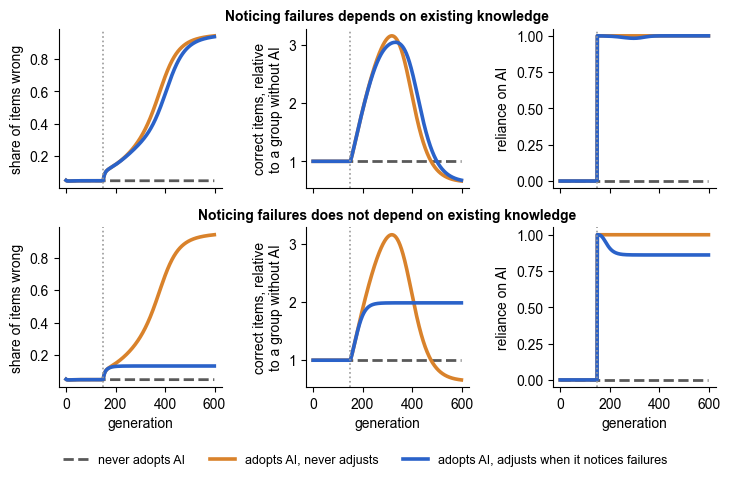

In [9]:
TOL, SPEED = 0.15, 0.1
pick = lambda noticing, speed: [d for d in trajectories if d.noticing.iloc[0] == noticing and d.speed.iloc[0] == speed and d.tolerance.iloc[0] == TOL][0]
fig, ax = plt.subplots(2, 3, figsize=(7.4, 4.8), sharex=True)
for row, (noticing, title) in enumerate([('depends on knowledge', 'Noticing failures depends on existing knowledge'),
                                         ('regardless of knowledge', 'Noticing failures does not depend on existing knowledge')]):
    never, adjusts = pick(noticing, 0), pick(noticing, SPEED)
    # correct items are shown relative to the protected group at the same generation, so the scale has a meaning of its own
    y = lambda d, col: d[col] / protected[col].values if col == 'correct' else (d[col] if col in d else 0 * d.gen)
    for x, col in zip(ax[row], ['share_wrong', 'correct', 'reliance']):
        x.plot(protected.gen, y(protected, col), color='0.35', ls='--', lw=2, label='never adopts AI')
        x.plot(never.gen, y(never, col), color='#d9822b', lw=2.6, label='adopts AI, never adjusts')
        x.plot(adjusts.gen, y(adjusts, col), color='#2a62c9', lw=2.6, label='adopts AI, adjusts when it notices failures')
        x.set_xticks([0, 200, 400, 600])
        x.axvline(SWITCH, color='0.6', ls=':', lw=1.2)
    ax[row, 1].set_title(title, fontsize=10, fontweight='bold')
    ax[row, 0].set_ylabel('share of items wrong'); ax[row, 1].set_ylabel('correct items, relative\nto a group without AI'); ax[row, 2].set_ylabel('reliance on AI')
for x in ax[1]: x.set_xlabel('generation')
h, l = ax[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(f'{OUT}/figure1.png', dpi=300); plt.show()

## 10. Agent-based check of the equations

The equations treat every person and item as average. Here each of 50 people holds a belief about every item, tests 100 items at random, interprets each test through their own share of wrong beliefs, and the next generation copies item by item, from a tester with probability $r$ (if anyone tested the item) and otherwise from a random person. The group switches to the weak mechanisms at generation 100. Four random seeds are compared with the equations.

In [10]:
def agent_based(M, r, f, T=350, switch_at=100, after=WEAK, seed=0, prm=BASE):
    N, E, EPS, A, P0, G = (prm[k] for k in ['N', 'E', 'EPS', 'A', 'P0', 'G'])
    rng = np.random.default_rng(seed)
    B = rng.random((N, K0)) < W0                           # True = wrong belief
    rows = []
    for t in range(T):
        p = dict(M=M, r=r, f=f) if t < switch_at else after
        K = B.shape[1]; w_pop = B.mean()
        rows.append((t, K, w_pop, K * (1 - w_pop)))
        tested = np.zeros((N, K), bool)
        for i in range(N): tested[i, rng.integers(0, K, E)] = True
        read_i = A + (1 - A) * (1 - B.mean(axis=1)) ** p['M']          # each person reads through their own beliefs
        B = B & ~(tested & B & (rng.random((N, K)) < read_i[:, None]))
        any_t = tested.any(axis=0)
        keep = any_t | (rng.random(K) >= p['f'])                        # items nobody tested fade
        B, tested, any_t = B[:, keep], tested[:, keep], any_t[keep]; K = B.shape[1]
        newB = np.empty_like(B)
        for j in range(N):                                             # each learner copies each item
            from_tester = np.where(tested, rng.random((N, K)), -1.0).argmax(axis=0)
            random_teacher = rng.integers(0, N, K)
            use = (rng.random(K) < p['r']) & any_t
            newB[j] = B[np.where(use, from_tester, random_teacher), np.arange(K)]
        newB |= rng.random(newB.shape) < EPS                           # copying error
        read_pop = A + (1 - A) * (1 - newB.mean()) ** p['M']
        new = np.repeat((rng.random(G) >= P0 * read_pop)[None, :], N, axis=0)
        B = np.concatenate([newB, new], axis=1)
    return pd.DataFrame(rows, columns=['gen', 'stock', 'share_wrong', 'correct'])

eq10 = run(**STRONG, T=350, switch_at=100, after=WEAK)
sims = pd.concat([agent_based(**STRONG, seed=s).assign(seed=s) for s in range(4)])
sims.to_csv(f'{OUT}/s10_agent_based.csv', index=False)
m = sims.groupby('gen')[['stock', 'share_wrong']].mean()
s10 = pd.DataFrame({'gen': eq10.gen, 'share_wrong_equations': eq10.share_wrong, 'share_wrong_agents': m.share_wrong.values,
                    'stock_equations': eq10.stock, 'stock_agents': m.stock.values})
s10.to_csv(f'{OUT}/s10_comparison.csv', index=False)
print(s10.iloc[[0, 50, 99, 150, 200, 250, 300, 349]].round(3).to_string(index=False))
print('largest difference in share wrong:', round(float((s10.share_wrong_equations - s10.share_wrong_agents).abs().max()), 3))

 gen  share_wrong_equations  share_wrong_agents  stock_equations  stock_agents
   0                  0.050               0.051         1000.000       1000.00
  50                  0.047               0.048         2207.019       2216.75
  99                  0.048               0.047         2265.865       2259.25
 150                  0.148               0.145         4765.986       4760.75
 200                  0.212               0.208         7265.986       7260.75
 250                  0.312               0.308         9765.986       9760.75
 300                  0.473               0.460        12265.986      12260.75
 349                  0.685               0.669        14715.986      14710.75
largest difference in share wrong: 0.018


## 11. The tipping point

Section 7 shows that, with weak mechanisms, the share of wrong items can settle in a mostly correct or a mostly wrong state. This section asks when the group that learns through AI (Section 4) loses the mostly correct one, and compares that moment with the peak of correct items. Two checks:

1. **Resting points.** For a stock of a given size, with all three mechanisms weak, find the shares of wrong items that one generation (including new items) leaves unchanged. Beyond some stock size, the mostly correct resting point disappears.
2. **Stopping growth.** At each generation after the switch, stop the stock from growing (no new items, nothing forgotten) while the group keeps learning through AI, and run until the share of wrong items settles. The last generation from which it still settles in the mostly correct state is the point of no return for a group that keeps relying on AI.

Section 12 checks whether a group that reduces its reliance on AI can still recover after this point.

In [11]:
a = with_ai[with_ai.gen >= SWITCH]; peak = int(a.correct.idxmax())
below = int(a.gen[(a.gen > peak) & (a.correct < protected.correct[a.index])].iloc[0])

# 1. resting points of one generation at fixed stock, all three mechanisms weak
wsg = np.linspace(1e-6, 1 - 1e-6, 20001)
rp = []
for K in np.logspace(np.log10(500), np.log10(2e5), 500):
    h = step(wsg, K, **WEAK)[0] - wsg
    for i in np.where(np.sign(h[:-1]) != np.sign(h[1:]))[0]:
        rp.append(dict(stock=K, share_wrong=wsg[i], stable=bool(h[i] > 0 > h[i + 1])))
rp = pd.DataFrame(rp); rp.to_csv(f'{OUT}/s11_resting_points.csv', index=False)
K_fold = rp[rp.stable & (rp.share_wrong < 0.5)].stock.max()
g_fold = int(a[a.stock > K_fold].gen.iloc[0])

# 2. stop the stock growing at each generation, keep learning through AI
def settles(t, gens=3000):
    w, K = with_ai.share_wrong[t], with_ai.stock[t]
    for _ in range(gens):
        w, K = step(w, K, **WEAK, g=0)
    return w
stop = pd.DataFrame([dict(gen=t, share_wrong=with_ai.share_wrong[t], settles_at=settles(t)) for t in range(SWITCH, T)])
stop.to_csv(f'{OUT}/s11_stop_growth.csv', index=False)
g_last = int(stop[stop.settles_at < 0.5].gen.max())

s11 = pd.Series({'mostly correct resting point exists up to stock': K_fold,
                 'generation at which the group passes that stock': g_fold,
                 'share wrong then': with_ai.share_wrong[g_fold],
                 'correct items then, relative to protected': with_ai.correct[g_fold] / protected.correct[g_fold],
                 'last generation from which stopping growth still settles mostly correct': g_last,
                 'settles at, stopping at that generation': stop.set_index('gen').settles_at[g_last],
                 'settles at, stopping one generation later': stop.set_index('gen').settles_at[g_last + 1],
                 'every later generation settles mostly wrong': bool((stop[stop.gen > g_last].settles_at > 0.5).all()),
                 'generation of peak correct items': peak,
                 'generation correct items fall below protected': below})
s11.to_csv(f'{OUT}/s11_tipping_point.csv'); print(s11.to_string())

mostly correct resting point exists up to stock                            7274.689298
generation at which the group passes that stock                                    251
share wrong then                                                              0.214118
correct items then, relative to protected                                     2.662597
last generation from which stopping growth still settles mostly correct            293
settles at, stopping at that generation                                        0.36211
settles at, stopping one generation later                                      0.87775
every later generation settles mostly wrong                                       True
generation of peak correct items                                                   318
generation correct items fall below protected                                      477


## 12. Recovery after the tipping point

Section 11 shows that, after a certain generation, a group that keeps relying on AI can no longer return to a mostly correct state even if its stock stops growing. This section asks whether reducing reliance on AI still allows recovery after that point. Two checks:

1. **Resting points with strong mechanisms.** As in Section 11, but with all three mechanisms strong: the number of stable shares of wrong items that one generation (including new items) leaves unchanged, for stocks of each size.
2. **Reducing reliance.** At every fifth generation after the switch, and at the point of no return of Section 11 and the generation after it, the group reduces its reliance on AI to $\rho$ (0 = back to learning from people and experience; each mechanism takes a value between its strong and weak levels in proportion to $\rho$), and runs until the share of wrong items settles. For each $\rho$: whether the group returns to a mostly correct state (less than half of items wrong) from every starting generation, the last starting generation from which it does, and where it settles when it starts at the end of the run.

In [12]:
# 1. resting points of one generation at fixed stock, all three mechanisms strong
wsg = np.linspace(1e-6, 1 - 1e-6, 20001)
n_stable = []
for K in np.logspace(np.log10(500), np.log10(2e5), 500):
    h = step(wsg, K, **STRONG)[0] - wsg
    idx = np.where(np.sign(h[:-1]) != np.sign(h[1:]))[0]
    n_stable.append(int(sum(h[i] > 0 > h[i + 1] for i in idx)))
print('stable resting points with strong mechanisms, at any stock from 500 to 200,000:', sorted(set(n_stable)))

# 2. reduce reliance at a given generation and run until the share wrong settles
def after_reducing(t, rho, gens=3000):
    m = {k: STRONG[k] + rho * (WEAK[k] - STRONG[k]) for k in ['M', 'r', 'f']}
    w, K = with_ai.share_wrong[t], with_ai.stock[t]
    for _ in range(gens):
        w_prev, (w, K) = w, step(w, K, **m)
    return w, abs(w - w_prev)

starts = sorted(set(range(SWITCH, T, 5)) | {g_last, g_last + 1, T - 1})
rows = []
for rho in [0.0, 0.5, 0.9]:
    for t in starts:
        w_end, change = after_reducing(t, rho)
        rows.append(dict(reliance=rho, start=t, share_wrong_at_start=with_ai.share_wrong[t], settles_at=w_end, last_change=change))
s12 = pd.DataFrame(rows); s12.to_csv(f'{OUT}/s12_recovery.csv', index=False)
print('largest change in the last generation of any run (should be near 0):', f'{s12.last_change.max():.1e}')

summary = []
for rho, d in s12.groupby('reliance'):
    ok = d[d.settles_at < 0.5]
    summary.append({'reliance': rho, 'recovers from every start': bool(len(ok) == len(d)),
                    'last start that recovers': int(ok.start.max()) if len(ok) else None,
                    'settles at, starting at the point of no return + 1': d.set_index('start').settles_at[g_last + 1],
                    'settles at, starting at the end of the run': d.set_index('start').settles_at[T - 1]})
summary = pd.DataFrame(summary).set_index('reliance')
summary.to_csv(f'{OUT}/s12_recovery_summary.csv')
print('point of no return for a group that keeps relying on AI (Section 11):', g_last)
print(summary.to_string())

stable resting points with strong mechanisms, at any stock from 500 to 200,000: [1]
largest change in the last generation of any run (should be near 0): 0.0e+00
point of no return for a group that keeps relying on AI (Section 11): 293
          recovers from every start  last start that recovers  settles at, starting at the point of no return + 1  settles at, starting at the end of the run
reliance                                                                                                                                                     
0.0                            True                       599                                            0.047521                                    0.047521
0.5                            True                       599                                            0.070009                                    0.070009
0.9                           False                       350                                            0.160573                    